In [1]:
# ============================================================
# LOAD DATA AND BUILD THE WAWQI TARGET (single shared pipeline)
# ============================================================
# All index math, standards, cleaning and classification live in the
# project-root module `wawqi.py`. This notebook, notebooks/eval_experiments.ipynb
# and app.py all import the SAME module, so the target and the feature order
# can never diverge between training and serving.

import os, sys
sys.path.insert(0, os.path.abspath(".."))   # notebooks/ runs one level down

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import wawqi

df = pd.read_csv("../data/water_dataX.csv", encoding="latin1")
print("RAW rows:", len(df))

# Canonical feature order == wawqi.PARAMS (the 7 Brown WAWQI parameters).
FEATURES = wawqi.PARAMS
print("Features (n=%d):" % len(FEATURES))
for f in FEATURES:
    print("   -", f)

# Documented cleaning + WAWQI target. Removes only DEMONSTRABLY impossible
# records (pH outside [0,14]; negative values); polluted samples are KEPT,
# unlike Paper 6's permissible-range filter that discarded them.
wqi_df, info = wawqi.clean_and_index(df)

print("\nCleaning chain:")
print("  raw                      :", info["raw"])
print("  - impossible records    ->", info["after_invalid"], "(removed %d)" % info["removed_impossible"])
print("  - all-column duplicates ->", info["after_invalid"] - info["removed_allcol_dupes"], "(removed %d)" % info["removed_allcol_dupes"])
print("  - missing (complete-case)->", info["after_dropna"], "(removed %d)" % info["removed_missing"])
print("  - duplicate vectors     ->", info["final_n"], "(removed %d)" % info["removed_vector_dupes"])
print("  FINAL N                  :", info["final_n"])

print("\nFeature ranges:")
print(wqi_df[FEATURES].describe().T[["min", "50%", "mean", "max"]])

# ============================================================
# wqi_df (features + WQI target) IS READY FOR MODELLING
# ============================================================

RAW rows: 1991
Features (n=7):
   - D.O. (mg/l)
   - PH
   - CONDUCTIVITY (µmhos/cm)
   - B.O.D. (mg/l)
   - NITRATENAN N+ NITRITENANN (mg/l)
   - FECAL COLIFORM (MPN/100ml)
   - TOTAL COLIFORM (MPN/100ml)Mean

Cleaning chain:
  raw                      : 1991
  - impossible records    -> 1902 (removed 89)
  - all-column duplicates -> 1901 (removed 1)
  - missing (complete-case)-> 1572 (removed 329)
  - duplicate vectors     -> 1571 (removed 1)
  FINAL N                  : 1571

Feature ranges:
                                   min      50%           mean           max
D.O. (mg/l)                        0.0    6.633       6.307705  1.000000e+01
PH                                 2.6    7.200       7.174840  9.010000e+00
CONDUCTIVITY (µmhos/cm)           11.0  182.000    1860.702756  4.715600e+04
B.O.D. (mg/l)                      0.1    1.780       5.224080  5.345000e+02
NITRATENAN N+ NITRITENANN (mg/l)   0.0    0.510       1.400390  5.810000e+01
FECAL COLIFORM (MPN/100ml)         0.0

## Water Quality Index used in this project: Brown-style Weighted Arithmetic WQI

This project computes a **Weighted Arithmetic Water Quality Index (WAWQI)**
following the framework of **Brown et al. (1972)**, the same family of index
described in Paper 6 (`article6.pdf`, "Calculation of WQI", Eqs 1-4; limits in
supplementary `t1.docx` Table 2S, classification in Table 1S). It is a
**corrected, scientifically defensible re-implementation**, not a byte-exact
reproduction of Paper 6's code (deviations listed below).

### Equations

For each parameter *i* a sub-index \(q_i\) is scored so that \(q_i = 0\) at
the ideal value and \(q_i = 100\) at the permissible limit:

* higher-is-worse (ideal 0) - EC, BOD, Nitrate, Fecal & Total coliform:
  \[ q_i = 100 \cdot \dfrac{V_i}{S_i} \]
* **Dissolved Oxygen** (higher-is-better; standard is a *minimum*):
  \[ q_{DO} = 100 \cdot \dfrac{V_{ideal} - V}{V_{ideal} - S_{min}}, \quad V_{ideal}=14.6 \]
* **pH** (two-sided about 7):
  \[ q_{pH} = 100 \cdot \dfrac{|V_i - 7|}{S_i - 7} \]

Unit weights are inverse-permissible-value, and the index is the weight-normalised
mean of the sub-indices:

\[ w_i = \dfrac{k}{S_i}, \qquad \text{WQI} = \dfrac{\sum_i q_i w_i}{\sum_i w_i} \]

### Direction

**LOWER WQI = BETTER water** (0-25 Excellent, 25-50 Good, 50-75 Poor,
75-100 Very Poor). This is verified in the pipeline report cell: the index
correlates *negatively* with dissolved oxygen and *positively* with BOD.

### Standards used (see `wawqi.py` for per-parameter provenance)

| Parameter | Ideal | Permissible S | Source |
|---|---|---|---|
| Dissolved Oxygen (mg/L) | 14.6 | >= 6.0 (min) | CPCB Class A |
| pH | 7.0 | 6.5-8.5 | general surface-water band |
| Conductivity (uS/cm) | 0 | <= 1000 | adopted guideline (NOT a Class A figure) |
| BOD (mg/L) | 0 | <= 2.0 | CPCB Class A |
| Nitrate+Nitrite (mg/L as N) | 0 | <= 11.3 | WHO 50 mg/L as NO3 x 0.2259 |
| Fecal coliform (MPN/100mL) | 0 | <= 50 | consistent with Class A total-coliform |
| Total coliform (MPN/100mL) | 0 | <= 50 | CPCB Class A |

### Documented deviations from Paper 6's `t2.docx` implementation

1. **DO** uses a *minimum* standard in the inverted form. The paper used
   S_DO = 10 as an upper cap with ideal 14.6, forcing q_DO >= 100 for every
   in-range sample (sign/range defect).
2. **pH** uses \(|V - ideal|\). The paper omitted the absolute value, giving
   *negative* sub-indices for pH < 7.
3. Sub-indices are **clipped to [0, 100]**; the paper applied no bounds.
4. **Nitrate** standard is on the same **as-N** basis as the data column. The
   paper applied 45 mg/L (an as-NO3 figure) to an as-N column (unit-basis error).
5. **Cleaning keeps polluted samples**: only demonstrably impossible records are
   removed. The paper's 390-row pipeline additionally filtered every row to
   within permissible ranges before computing the index, discarding the samples
   a WQI model must learn from.

The index is an **aggregate screening indicator**, not a potability
certification.

In [2]:
# ============================================================
# WAWQI TARGET REPORT
# ============================================================
# wqi_df["WQI"] was already computed by wawqi.clean_and_index in the first
# cell. Here we report the unit weights and the resulting target distribution,
# and re-confirm the lower-is-better direction independently of any model.

WEIGHT_SUM = 1.0   # unit weights are normalised, so max attainable WQI = 100

print("=" * 60)
print("UNIT WEIGHTS  w_i = (1/S_i) / sum_j(1/S_j)")
print("=" * 60)
wn = wawqi.normalized_weights()
for p in FEATURES:
    print("  %-40s S=%-8g  w=%.5f" % (p, wawqi.STANDARDS[p], wn[p]))

print("\n" + "=" * 60)
print("FINAL WQI STATISTICS  (0-100, LOWER = BETTER)")
print("=" * 60)
print(wqi_df["WQI"].describe())

print("\nDistinct WQI values:", wqi_df["WQI"].nunique(), "over", len(wqi_df), "rows")
print("WQI missing:", int(wqi_df["WQI"].isna().sum()))

print("\nClass distribution (Table 1S bands):")
print(wqi_df["WQI"].map(wawqi.classify_wqi).value_counts().to_string())

print("\n" + "=" * 60)
print("DIRECTION SANITY (must hold regardless of the model)")
print("=" * 60)
print("corr(WQI, DO ) = %.4f  (expected NEGATIVE: more DO -> lower/better WQI)"
      % np.corrcoef(wqi_df[wawqi.DO], wqi_df["WQI"])[0, 1])
print("corr(WQI, BOD) = %.4f  (expected POSITIVE: more BOD -> higher/worse WQI)"
      % np.corrcoef(wqi_df[wawqi.BOD], wqi_df["WQI"])[0, 1])

print("\nFINAL SHAPE:", wqi_df.shape)

UNIT WEIGHTS  w_i = (1/S_i) / sum_j(1/S_j)
  D.O. (mg/l)                              S=6         w=0.18239
  PH                                       S=8.5       w=0.12874
  CONDUCTIVITY (µmhos/cm)                  S=1000      w=0.00109
  B.O.D. (mg/l)                            S=2         w=0.54716
  NITRATENAN N+ NITRITENANN (mg/l)         S=11.3      w=0.09684
  FECAL COLIFORM (MPN/100ml)               S=50        w=0.02189
  TOTAL COLIFORM (MPN/100ml)Mean           S=50        w=0.02189

FINAL WQI STATISTICS  (0-100, LOWER = BETTER)
count    1571.000000
mean       67.961232
std        15.738242
min        22.386496
25%        54.535863
50%        72.879352
75%        81.299653
max        92.275387
Name: WQI, dtype: float64

Distinct WQI values: 1566 over 1571 rows
WQI missing: 0

Class distribution (Table 1S bands):
WQI
Very Poor    742
Poor         544
Good         284
Excellent      1

DIRECTION SANITY (must hold regardless of the model)
corr(WQI, DO ) = -0.3311  (expected NEGA

Training samples: 1256
Testing samples : 315

LEAKAGE AUDIT
Duplicate train/test parameter vectors: 0



MODEL COMPARISON
            Model       MAE      RMSE  R2 Score
Gradient Boosting  0.572678  0.758222  0.997752
    Random Forest  0.853020  1.250820  0.993883
    Decision Tree  1.210802  1.713308  0.988524
Linear Regression 12.079783 14.528193  0.174839



BEST HYPERPARAMETERS
{'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 150}

Best Cross-Validation R2:
0.9975140372032765

FINAL TUNED GRADIENT BOOSTING MODEL
MAE  : 0.4689715716050217
RMSE : 0.650407894399744
R²   : 0.998346183839889

ACTUAL VS PREDICTED
 Actual WQI  Predicted WQI
  58.618926      58.763209
  75.479664      76.313648
  48.215925      48.303186
  80.949721      80.541090
  85.474285      85.608459
  85.528736      85.337733
  80.727206      81.021854
  44.168809      43.836234
  75.330000      77.338460
  60.402514      59.751951
  47.024592      47.206716
  61.753444      60.942574
  46.789435      47.180405
  50.172914      50.560491
  79.050787      78.745144
  70.409407      71.888361
  47.131652      46.754512
  81.673827      81.664771
  41.617156      41.746868
  63.176300      62.759998


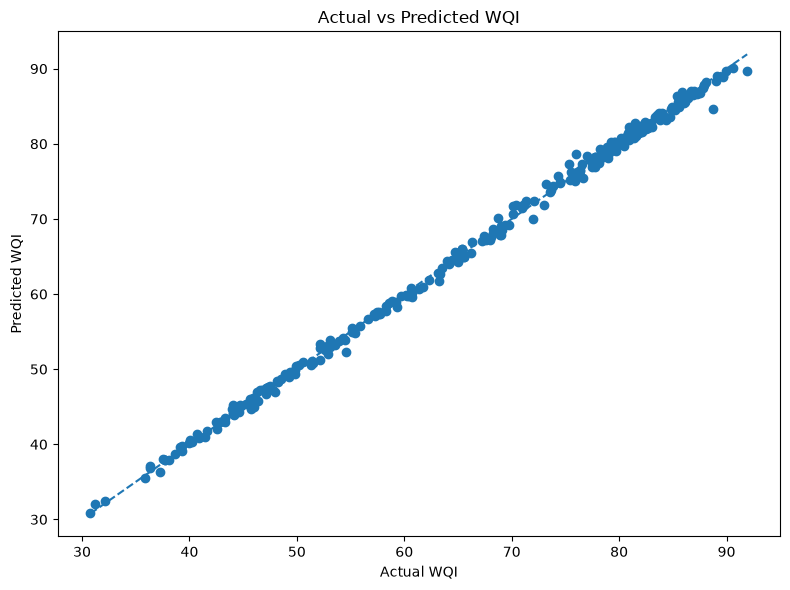


FEATURE IMPORTANCE
                         Feature  Importance
                   B.O.D. (mg/l)    0.955791
                              PH    0.025199
                     D.O. (mg/l)    0.008624
NITRATENAN N+ NITRITENANN (mg/l)    0.007993
      FECAL COLIFORM (MPN/100ml)    0.001286
  TOTAL COLIFORM (MPN/100ml)Mean    0.001012
         CONDUCTIVITY (µmhos/cm)    0.000094


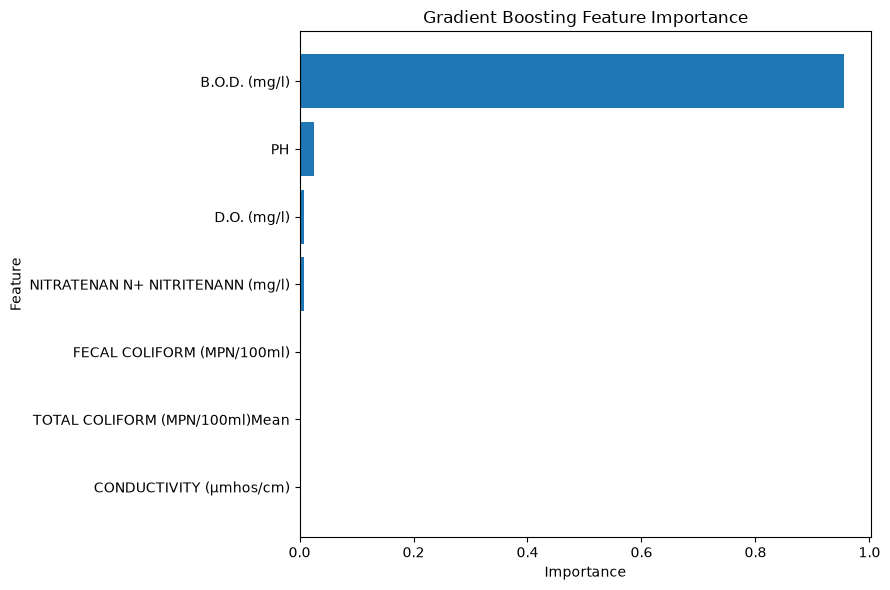


SHAP FEATURE IMPORTANCE


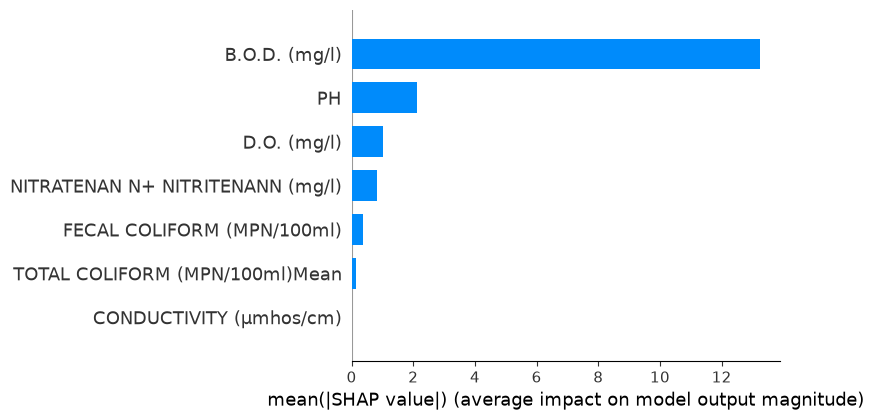


RUN MANIFEST
Samples            : 1571
Features           : 7
Train / Test       : 1256 / 315
Target max possible: 100.0
sklearn version    : 1.9.0
shap version       : 0.52.0


In [3]:
# ============================================================
# AI WATER QUALITY PREDICTION MODEL
# ============================================================

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import shap


# ============================================================
# FEATURES AND TARGET
# ============================================================
# FEATURES is the single 6-parameter list defined in the first cell,
# so data cleaning, WQI calculation and model training cannot diverge.

X = wqi_df[FEATURES]
y = wqi_df["WQI"]


# ============================================================
# TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

# ------------------------------------------------------------
# LEAKAGE AUDIT
# ------------------------------------------------------------
# Report any identical parameter vector that appears in both splits.
_keys = X.astype(str).agg("|".join, axis=1)
_leaked = int(_keys.loc[X_test.index].isin(_keys.loc[X_train.index]).sum())

print("\n" + "=" * 60)
print("LEAKAGE AUDIT")
print("=" * 60)
print("Duplicate train/test parameter vectors:", _leaked)


# ============================================================
# MODEL COMPARISON
# ============================================================

models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })


results_df = pd.DataFrame(results)

print("\n" + "=" * 60)
print("MODEL COMPARISON")
print("=" * 60)

print(
    results_df
    .sort_values("R2 Score", ascending=False)
    .to_string(index=False)
)


# ============================================================
# HYPERPARAMETER TUNING
# ============================================================

gb = GradientBoostingRegressor(random_state=42)

param_grid = {
    "n_estimators": [50, 100, 150],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

grid_search = GridSearchCV(
    gb,
    param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("\n" + "=" * 60)
print("BEST HYPERPARAMETERS")
print("=" * 60)

print(grid_search.best_params_)

print("\nBest Cross-Validation R2:")
print(grid_search.best_score_)


# ============================================================
# FINAL TUNED MODEL
# ============================================================

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n" + "=" * 60)
print("FINAL TUNED GRADIENT BOOSTING MODEL")
print("=" * 60)

print("MAE  :", mae)
print("RMSE :", rmse)
print("R²   :", r2)


# ============================================================
# ACTUAL VS PREDICTED
# ============================================================

comparison = pd.DataFrame({
    "Actual WQI": y_test.values,
    "Predicted WQI": y_pred
})

print("\n" + "=" * 60)
print("ACTUAL VS PREDICTED")
print("=" * 60)

print(comparison.head(20).to_string(index=False))


# ============================================================
# ACTUAL VS PREDICTED PLOT
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual WQI")
plt.ylabel("Predicted WQI")
plt.title("Actual vs Predicted WQI")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.tight_layout()
plt.show()


# ============================================================
# FEATURE IMPORTANCE
# ============================================================

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print("\n" + "=" * 60)
print("FEATURE IMPORTANCE")
print("=" * 60)

print(importance.to_string(index=False))


# ============================================================
# FEATURE IMPORTANCE PLOT
# ============================================================

plt.figure(figsize=(9, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Gradient Boosting Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


# ============================================================
# SHAP ANALYSIS
# ============================================================

explainer = shap.TreeExplainer(best_model)

shap_values = explainer.shap_values(X_test)

print("\n" + "=" * 60)
print("SHAP FEATURE IMPORTANCE")
print("=" * 60)

shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar"
)


# ============================================================
# RUN MANIFEST
# ============================================================

print("\n" + "=" * 60)
print("RUN MANIFEST")
print("=" * 60)
print("Samples            :", len(wqi_df))
print("Features           :", len(FEATURES))
print("Train / Test       :", len(X_train), "/", len(X_test))
print("Target max possible:", 100 * WEIGHT_SUM)
print("sklearn version    :", sklearn.__version__)
print("shap version       :", shap.__version__)

In [4]:
import joblib

joblib.dump(best_model, "../model/wqi_model.pkl")
joblib.dump(FEATURES, "../model/features.pkl")

print("Model saved successfully!")
print("Model type      :", type(best_model).__name__)
print("n_features_in_  :", best_model.n_features_in_)
print("Features written:", FEATURES)

Model saved successfully!
Model type      : GradientBoostingRegressor
n_features_in_  : 7
Features written: ['D.O. (mg/l)', 'PH', 'CONDUCTIVITY (µmhos/cm)', 'B.O.D. (mg/l)', 'NITRATENAN N+ NITRITENANN (mg/l)', 'FECAL COLIFORM (MPN/100ml)', 'TOTAL COLIFORM (MPN/100ml)Mean']
